# 1. Exploratory data analysis

**Goal:** check every fact the spec marks *verify in EDA* against the real file, and see why
each one shapes the design.

You will see: the size of the file, the share of randomly ranked searches, the selection on
clicks, how bookings differ by arm, the reserved positions, zero-coded values and price outliers.

Firewall note: this notebook shows click rates per **arm**, but never click rates by **position**
in the randomly ranked arm, because that would reveal the benchmark before the specification is fixed.

## Setup

Imports and configuration. Every threshold and setting comes from `config.yaml`. Set `SYNTHETIC = True` to run on the synthetic file built by `python -m causallab prepare --synthetic`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import json
import numpy as np
import pandas as pd
from causallab.config import load_config, load_spec, results_dir

cfg = load_config()
SYNTHETIC = False   # True = run on the synthetic Expedia-like file (no Kaggle data needed)
pd.set_option("display.width", 140)

## The Phase 1 checks

**What:** one query per *verify in EDA* item, run with DuckDB directly on the full Parquet file
(about 10 million rows) without loading it into memory.

**Why:** the spec says the data wins. Each finding below changed a design decision.

**Expect:** about 9.9 million rows, roughly 30% randomly ranked searches, zero searches without a
click, and four reserved positions.

In [2]:
from causallab.eda import run_eda
eda = run_eda(cfg, SYNTHETIC, save=False)  # computed here, not written over results/
for line in eda["findings"]:
    print("-", line)

- Rows: 9,917,530; searches: 399,344 (spec: about 9.9 million rows).
- Randomly ranked share of searches: 30.4% (spec: roughly one third).
- Share of searches with zero clicks: arm 0 = 0.0%, arm 1 = 0.0% (spec: only searches with a click are in the file).
- Share of searches with a booking: arm 0 = 93.9%, arm 1 = 13.0% (spec: bookings sampled differently across arms).
- Reserved positions (under a quarter of the usual rows in both arms): [5, 11, 17, 23] (config: [5, 11, 17, 23]).
- Zero-coded states: star 3.4%, review 4.7% (plus 0.15% null), historical price 14.4%.
- Price: 99.9th percentile 2,133, maximum 19,726,328 (winsorise).
- Arms differ on search covariates: arm 0: stay 2.16 nights, window 32.7 days; arm 1: stay 2.94 nights, window 49.4 days


## Rows by position and arm

**What:** how many rows sit at each position, separately for algorithm-ranked (observational) and
randomly ranked (experimental) searches.

**Why:** positions that almost never appear in either arm are reserved for other listing types.
Comparing top-3 with a control group that includes them would compare different kinds of listing.

**Expect:** sharp dips at positions 5, 11, 17 and 23 in both arms.

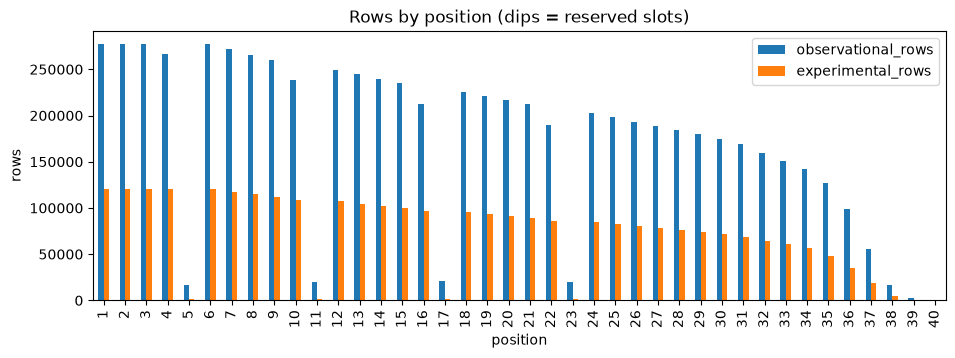

In [3]:
pos = pd.DataFrame(eda["rows_by_position"]).set_index("position")
ax = pos.plot(kind="bar", figsize=(11, 3.5), title="Rows by position (dips = reserved slots)")
ax.set_ylabel("rows");

## Selection: every search has a click

**What:** the share of searches with zero clicks, and the share with a booking, per arm.

**Why:** Expedia only released searches with at least one click, so every rate in this project is
*conditional on the search producing a click*. Bookings were sampled very differently in the two
arms, which is why click, not booking, is the primary outcome.

**Expect:** 0% zero-click searches in both arms; roughly 94% vs 13% of searches with a booking.

In [4]:
pd.DataFrame(eda["searches"]).assign(arm=lambda d: d.random_bool.map({0: "observational", 1: "experimental"}))

,random_bool,share_zero_click,share_with_booking,arm
0,0,0.0,0.938624,observational
1,1,0.0,0.130362,experimental


## Building the sample and the features

**What:** keep 50.5% of searches (`sample_fraction` in `config.yaml`; whole searches, chosen by a hash of `srch_id`), then build features.

**Why:** rows in a search are not independent, so we always sample, split and bootstrap by search.
Within-search features (price rank, price relative to the page median, quality relative to the
page, number of results) are computed on the **whole page** before any position filter, because
the user saw the whole page and the ranker scored all of it.

**Expect:** about 5 million rows in about 200,000 searches across both arms. The cell prints the
algorithm-ranked arm only (about 3.5 million rows in 140,000 searches). Zero-coded states get their own flags.
The features file is built only if it is missing (`python -m causallab prepare` rebuilds it).

In [5]:
from causallab import data, features
if not SYNTHETIC:
    sample = data.build_sample(cfg=cfg)          # skips if the file already exists
else:
    sample = data.sample_path(cfg, True)
fpath = data.features_path(cfg, SYNTHETIC)
if not fpath.exists():  # built once; rebuilding here would rewrite the file every result comes from
    features.build_features(sample, fpath, cfg)
obs = data.load_arm("observational", cfg, SYNTHETIC)
print(f"observational rows: {len(obs):,}  searches: {obs.srch_id.nunique():,}")
obs[["star_zero", "review_zero", "review_missing", "hist_price_zero", "loc2_missing", "affinity_missing"]].mean().round(3)

observational rows: 3,523,396  searches: 140,433


star_zero           0.033
review_zero         0.041
review_missing      0.001
hist_price_zero     0.145
loc2_missing        0.215
affinity_missing    0.925
dtype: float64

## The Q1 analysis rows

**What:** positions 1-3 (treated) against positions 4-10 without the reserved slot 5 (control).

**Why:** keeping the control group to positions 4-10 means both arms compare the same mix of
positions; position 25 would be a very different control from position 4.

**Expect:** about 1.2 million rows, about a third of them treated.

In [6]:
q1 = features.q1_rows(obs)
print(f"Q1 rows: {len(q1):,}; treated share {q1.top3.mean():.1%}; positions used: {sorted(q1.position.unique())}")

Q1 rows: 1,218,303; treated share 34.6%; positions used: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
